# K Nearest Neighbours

### Author
   * Jonathan Sancho Loaiza

### Running this notebook

It runs unchanged in Google Colab and on a local Jupyter installation. Every
library it uses, pandas, numpy, scikit-learn, seaborn, matplotlib and joblib, is
already installed in Colab, so there is nothing to `pip install`.

The only thing the notebook needs is the file `glass.csv`, the Glass
Identification dataset from Kaggle or the UCI repository. The loading cell reads
it from the notebook's own folder and, if it is not there, from Colab's
`sample_data` folder, so upload the CSV to either of those two places before
running.

Run the cells in order, with `Runtime > Run all`. The whole notebook takes about
a minute, and the grid search in the modelling section is the slowest part.

## Problem Analysis (CRISP-DM 1: Business Understanding)

A window breaks during a burglary and a fragment of that window ends up on the
sleeve of a suspect. The fragment is two millimetres wide, it carries no serial
number and it looks like every other piece of broken glass, but the question the
investigation has to answer is precise: does it come from a building window, a
car window, a bottle, a drinking glass or a headlamp? The answer decides whether
the fragment places the suspect at the scene or merely proves that they once
dropped a jar.

What a laboratory can measure on a fragment that small is its chemistry. A
refractive index reading and an elemental analysis give the proportion of sodium,
magnesium, aluminium, silicon, potassium, calcium, barium and iron in the piece.
Those eight oxides plus the refractive index are what this dataset records, for
214 fragments whose origin was already known, and the task is to turn that
composition into an origin.

The reason a model is worth building here is that the chemistry is not arbitrary.
Glass is manufactured to a recipe, and the recipe follows the use: a windscreen
has to survive being bent, so it is float glass with magnesium in it; a headlamp
has to stand heat, so it is a harder glass with barium; tableware is made without
potassium. Fragments of the same origin should therefore sit close together in
the space of the nine measurements, and fragments of different origin should sit
apart. That is exactly the assumption a **K Nearest Neighbours** classifier
makes, which is why it is the model chosen for this dataset: it does not fit an
equation, it looks at the known fragments nearest to the new one and lets them
vote.

Two properties of the problem shape everything that follows and are worth stating
before any code runs.

The first is that the classes are not equally frequent. Building windows account
for two thirds of the file and tableware for nine fragments. A model judged only
on how often it is right can reach a respectable score while never recognising a
single piece of tableware, so the evaluation has to be built on per class
measurements from the start.

The second is that not all confusions cost the same. Mixing up a container with a
headlamp is a visible error. Mixing up a building window with a vehicle window is
the error that matters in the case above, and those two are made by the same
float process out of nearly the same recipe. The notebook keeps that specific
confusion in view throughout.

### Libraries

In [1]:
# Dataset handling
import os
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Split and validation
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict,
                                     GridSearchCV)

# Evaluation
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score)

# Saving the model
import joblib

# Same split and same folds on every run
RANDOM_STATE = 1

pd.set_option('display.width', 160)
sns.set_style('whitegrid')

## Data Understanding (CRISP-DM 2)

The file `glass.csv` is the Glass Identification dataset that B. German collected
at the Home Office Forensic Science Service in the United Kingdom and that is
distributed through the UCI repository. Each row is one glass fragment whose
origin was established by other means, and each column one measurement taken on
it in the laboratory.

In [2]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
FILE = 'glass.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
glass = pd.read_csv(path)

# First records
glass.head()


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


The first rows show that every column is a number, which is unusual and makes the
preparation short. There is no text, no date and no identifier.

`RI` is the refractive index, the ratio between the speed of light in vacuum and
its speed inside the glass, and it is the one measurement that is not a
composition. The eight columns that follow, from `Na` to `Fe`, are the weight
percentages of the corresponding oxide in the fragment, so they are all read on
the same physical scale and, being percentages of the same material, they are not
independent of each other: a fragment rich in silicon has to be poor in something
else.

`Type` is the column to predict. It is written as a whole number from 1 to 7, but
that number is a name and not a quantity. Type 7 is not seven times type 1, and
the difference between 1 and 7 is not larger than the difference between 1 and 2.
Since KNN computes distances on the predictors only and uses the target just to
vote, this causes no trouble here, but it is the reason the column is never fed
to a distance.

In [3]:
# Number of records
print("Record count:", len(glass))
# Number of columns
print("Column count:", len(glass.columns))
# Rows and columns
print("Rows and columns:", glass.shape)
# Dataset information
glass.info()

Record count: 214
Column count: 10
Rows and columns: (214, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


The dataset has 214 records and 10 columns, so 9 possible predictors plus the
response. That is a small file by any standard, and its size is the constraint
that shapes the modelling section: with 214 fragments split into six origins, a
single train test split gives a test set of a few dozen rows, and a difference of
two correct answers moves the accuracy by three points. Every choice made later
is therefore validated by repeated cross validation rather than on one split.

The `info()` output reports 214 non null values for all ten columns and assigns
`float64` to the nine measurements and `int64` to `Type`, which is consistent
with a laboratory file: the measurements are continuous readings and the label is
a code.

In [4]:
# Check for empty values
print("Columns with an empty cell:", glass.isnull().any().sum(),
      ' / ', len(glass.columns))
print(glass.isnull().sum())

Columns with an empty cell: 0  /  10
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64


No column has an empty cell. This file is not a survey where people can decline
to answer, it is a set of laboratory measurements, and a fragment that could not
be measured never entered the database. The usual work of imputing or dropping
incomplete records does not apply here.

That does not mean every value is informative, and the exploration section comes
back to the columns that are full of zeros, because a zero in a percentage column
is a measurement and not a gap.

In [5]:
# Check for duplicated records
print("Duplicated rows:", glass.duplicated().sum())

# The records involved, so it is possible to see what they look like
glass[glass.duplicated(keep=False)]

Duplicated rows: 1


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
38,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1
39,1.52213,14.21,3.82,0.47,71.77,0.11,9.57,0.0,0.0,1


There is one repeated row, and printing both copies shows the pair: records 38
and 39 carry the same nine measurements down to the last decimal, `RI` 1.52213,
`Na` 14.21, `Mg` 3.82, and the same label, type 1.

Nine continuous readings agreeing to five decimal places is not a coincidence
between two different fragments, it is the same fragment written twice. The
concern is also practical and independent of that reading: a row present twice
can land in the training set and in the test set at once, and a KNN asked to
classify a test fragment that also sits in the training data finds itself at
distance zero from its own copy. Its first neighbour would then be itself, and
the test score would be measuring memory rather than generalisation.

One copy is kept.

In [6]:
# One copy of the repeated fragment is kept
glass = glass.drop_duplicates().reset_index(drop=True)
print("Records after removing duplicates:", len(glass))

Records after removing duplicates: 213


                                 Fragments  Share %
1 - Building windows, float             69     32.4
2 - Building windows, non float         76     35.7
3 - Vehicle windows, float              17      8.0
5 - Containers                          13      6.1
6 - Tableware                            9      4.2
7 - Headlamps                           29     13.6

Codes present in the file: [1, 2, 3, 5, 6, 7]


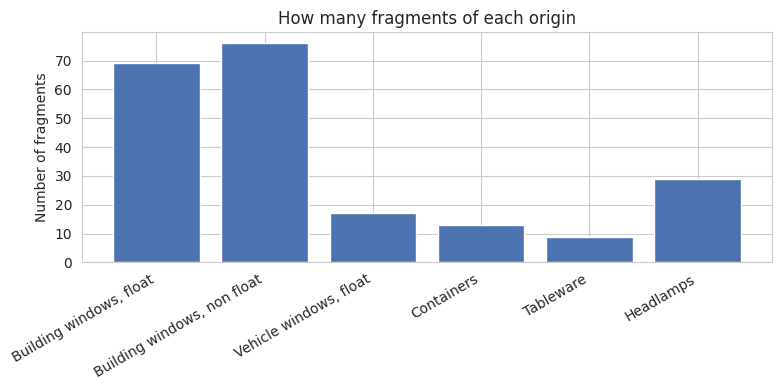

In [7]:
# The numeric codes of the target and what they name in the original database
TYPE_NAMES = {
    1: 'Building windows, float',
    2: 'Building windows, non float',
    3: 'Vehicle windows, float',
    4: 'Vehicle windows, non float',
    5: 'Containers',
    6: 'Tableware',
    7: 'Headlamps',
}

counts = glass['Type'].value_counts().sort_index()
share = (glass['Type'].value_counts(normalize=True).sort_index() * 100).round(1)
summary = pd.DataFrame({'Fragments': counts, 'Share %': share})
summary.index = [str(t) + ' - ' + TYPE_NAMES[t] for t in summary.index]
print(summary)
print("\nCodes present in the file:", [int(t) for t in sorted(glass['Type'].unique())])

plt.figure(figsize=(8, 4))
plt.bar([TYPE_NAMES[t] for t in counts.index], counts.values, color='#4c72b0')
plt.title('How many fragments of each origin')
plt.ylabel('Number of fragments')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

The bar chart counts fragments by origin and reports the first two facts that
govern the rest of the notebook.

The first is the imbalance. The two kinds of building window hold 69 and 76
fragments, together 68.1 percent of the file, while containers hold 13,
tableware 9 and vehicle windows 17. The smallest class is 4.2 percent of the
data. A classifier that answered building window to everything, ignoring all nine
measurements, would already be right 35.7 percent of the time, so 0.357 is the
floor against which any accuracy has to be read. More importantly, nine
fragments of tableware split into training and test leave two or three examples
to be judged on, which is why the evaluation reports per class figures and a
macro averaged F1 instead of a single accuracy.

The second is that type 4 is absent. The original database defines code 4 as
vehicle windows made by the non float process, and the file contains none: the
codes present are 1, 2, 3, 5, 6 and 7. So this is a six class problem, not seven,
and a model trained here cannot recognise a non float vehicle window at all. It
is worth stating explicitly because a gap in the codes usually signals a data
error, and here it does not.

## Data Exploration (CRISP-DM 2)

The exploration has to answer two questions. Which measurements separate the six
origins, and on what scale is each one read. The second question is not a detail
for a KNN: the model classifies by distance, and a distance adds the columns
together, so a column measured in larger numbers pushes harder on the result than
a column measured in smaller ones regardless of what it says about the glass.

In [8]:
# Summary of the nine measurements
glass.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
RI,213.0,1.518,0.003,1.511,1.517,1.518,1.519,1.534
Na,213.0,13.404,0.817,10.730,12.900,13.300,13.810,17.380
Mg,213.0,2.679,1.444,0.000,2.090,3.480,3.600,4.490
Al,213.0,1.449,0.496,0.290,1.190,1.360,1.630,3.500
Si,213.0,72.655,0.774,69.810,72.280,72.790,73.090,75.410
K,213.0,0.499,0.653,0.000,0.130,0.560,0.610,6.210
Ca,213.0,8.954,1.426,5.430,8.240,8.600,9.150,16.190
Ba,213.0,0.176,0.498,0.000,0.000,0.000,0.000,3.150
Fe,213.0,0.057,0.098,0.000,0.000,0.000,0.100,0.510
Type,213.0,2.789,2.105,1.000,1.000,2.000,3.000,7.000


Each row of this table is a measurement and each column a statistic: the count of
values, the mean, the standard deviation, the smallest value, the three quartiles
and the largest value.

The composition columns describe an ordinary soda lime glass. Silicon averages
72.7 percent, sodium 13.4 and calcium 9.0, which together make up 95 percent of
the material, and the remaining five oxides share what is left. The refractive
index averages 1.518.

The column to read next to those means is the standard deviation, and it is where
the nine measurements stop being comparable. `RI` moves within 0.003 of its mean
and spans 0.023 from its smallest to its largest value, while calcium spans 10.76
and sodium 6.65. That is a factor of about 470 between the widest and the
narrowest column, and it comes entirely from the units: the refractive index is a
ratio near 1 and the oxides are percentages of the whole. Nothing in that ratio
says the refractive index matters 470 times less for telling glasses apart.

Four columns also have a minimum of exactly zero, `Mg`, `K`, `Ba` and `Fe`, while
their maxima are far from it, `K` reaching 6.21 and `Ba` 3.15. The next cell
looks at those zeros, because in a percentage column a zero is a measurement, and
how often it occurs is itself information.

In [9]:
# A zero in a percentage column means the oxide is absent, not missing
zeros = (glass.drop(columns='Type') == 0).sum()
zeros = zeros[zeros > 0]
print("Fragments with the oxide completely absent:")
print(zeros)
print("\nShare of the file:")
print((zeros / len(glass) * 100).round(1))

# Which origins those zeros belong to
print("\nShare of fragments of each origin with no barium and with no magnesium:")
print(pd.DataFrame({
    'no Ba %': (glass[glass['Ba'] == 0].groupby('Type').size()
                / glass.groupby('Type').size() * 100).round(0),
    'no Mg %': (glass[glass['Mg'] == 0].groupby('Type').size()
                / glass.groupby('Type').size() * 100).round(0),
}).fillna(0))

Fragments with the oxide completely absent:
Mg     42
K      30
Ba    175
Fe    143
dtype: int64

Share of the file:
Mg    19.7
K     14.1
Ba    82.2
Fe    67.1
dtype: float64

Share of fragments of each origin with no barium and with no magnesium:
      no Ba %  no Mg %
Type                  
1        96.0      0.0
2        92.0     12.0
3        94.0      0.0
5        85.0     54.0
6       100.0     33.0
7        10.0     79.0


Barium is absent from 175 of the 213 fragments, 82.2 percent, iron from 143 and
magnesium from 42. Those are not missing values to be filled in: the laboratory
measured the fragment and found none of that oxide.

The breakdown by origin turns them into the first real signal of the notebook.
Barium is absent from 96, 92 and 94 percent of the three window types and from
100 percent of the tableware, but from only 10 percent of the headlamps. Put the
other way round, nine headlamps out of ten contain barium and almost nothing else
does, which is the chemistry of the problem showing through: headlamps are made
of a harder glass and barium enters that recipe.

Magnesium runs the other way. It is present in every float window, in 88 percent
of the non float ones, and absent from 54 percent of the containers, 33 percent
of the tableware and 79 percent of the headlamps. So the pair barium and
magnesium already draws a line between the windows and everything else, and a
second line between headlamps and the rest.

The catch is the size of the numbers. Barium averages 0.176 percent across the
file and never exceeds 3.15, against a calcium that reaches 16.19. On the raw
scale, the single most discriminating column of the dataset is also one of the
smallest, and a distance computed on raw values will barely hear it. The
preparation section measures that effect and corrects it.

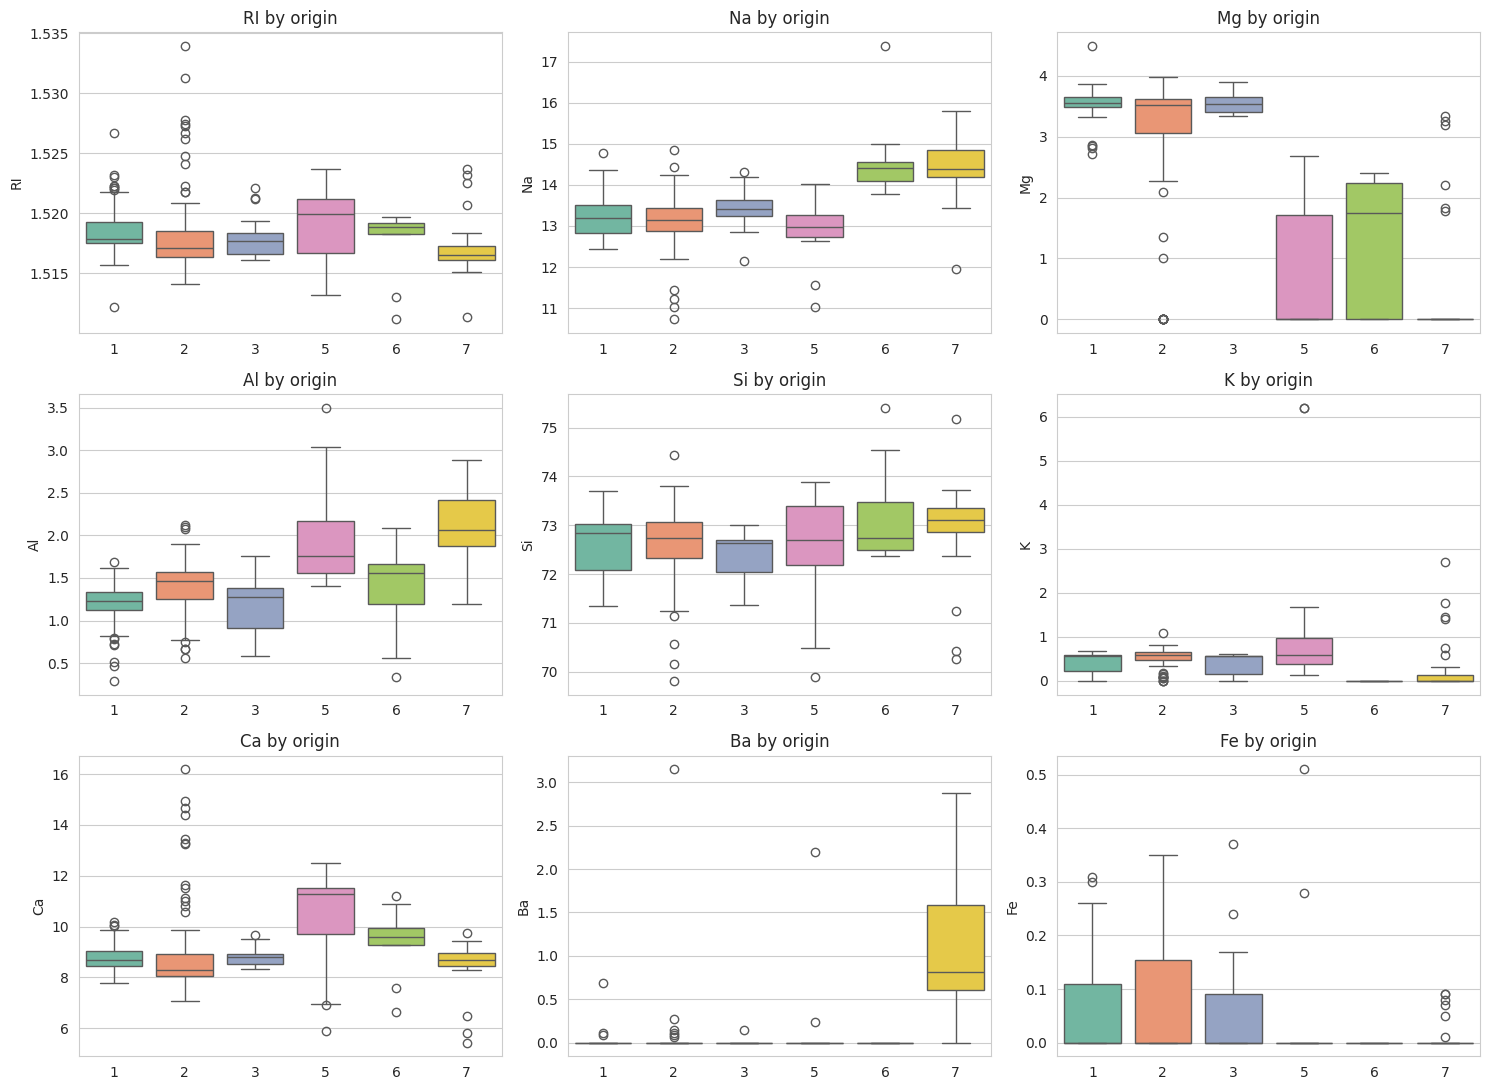

In [10]:
# Each measurement by origin, one panel per column
features = [c for c in glass.columns if c != 'Type']

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, column in zip(axes.ravel(), features):
    sns.boxplot(data=glass, x='Type', y=column, hue='Type', ax=ax,
                palette='Set2', legend=False)
    ax.set_title(column + ' by origin')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Each panel is a box plot of one measurement, with one box per origin. The box
covers the middle half of the fragments of that origin, the line inside it is the
median, the whiskers reach the values that are still close to the box and the
dots beyond are the fragments that sit far from the rest of their own group.

Read across the nine panels, three of them do most of the separating.

`Mg` splits the plot in two. Types 1, 2 and 3, the windows, sit as tight boxes
high up around a median of 3.5 percent, while types 5, 6 and 7 sit near the
bottom with long boxes that reach down to zero. `Ba` is the mirror image: five of
the six origins show a flat line at zero and only type 7 lifts off it, with a box
running from 0.61 to 1.59. `Al` rises from the windows, at medians of 1.23, 1.46
and 1.28, through the containers at 1.76 to the headlamps at 2.06. Those three
columns are what will let a KNN find headlamps, containers and tableware.

The panels also show where the model will struggle. Types 1, 2 and 3 have boxes
that overlap almost completely in every single panel. There is no measurement in
this dataset on which a float building window and a float vehicle window are
visibly different, and the three window types together are 76 percent of the
file. Whatever accuracy the model reaches, it will be decided inside that group.

`K` and `Ca` show a further complication: both have extreme values far above
their boxes, potassium reaching 6.21 against a median of 0.56 and calcium 16.19
against 8.60. They belong to genuine fragments and there is no reason to remove
them, but a KNN is sensitive to them, since a fragment sitting alone in a corner
of the space has no honest neighbours and will be classified by whatever happens
to be least far away.

In [11]:
# The average recipe of each origin, side by side
profile = glass.groupby('Type')[features].mean().round(3)
profile.index = [str(t) + ' - ' + TYPE_NAMES[t] for t in profile.index]
print(profile)

# How far apart the average recipes are, in standard deviations
scaled_profile = pd.DataFrame(
    StandardScaler().fit_transform(glass[features]), columns=features
).groupby(glass['Type']).mean()
gaps = {}
for a in scaled_profile.index:
    for b in scaled_profile.index:
        if a < b:
            gaps[str(a) + ' vs ' + str(b)] = np.abs(
                scaled_profile.loc[a] - scaled_profile.loc[b]).mean()
gaps = pd.Series(gaps).sort_values()
print("\nAverage gap between the mean profiles, in standard deviations:")
print(gaps.round(3))

                                    RI      Na     Mg     Al      Si      K      Ca     Ba     Fe
1 - Building windows, float      1.519  13.228  3.549  1.174  72.631  0.452   8.786  0.013  0.058
2 - Building windows, non float  1.519  13.112  3.002  1.408  72.598  0.521   9.074  0.050  0.080
3 - Vehicle windows, float       1.518  13.437  3.544  1.201  72.405  0.406   8.783  0.009  0.057
5 - Containers                   1.519  12.828  0.774  2.034  72.366  1.470  10.124  0.188  0.061
6 - Tableware                    1.517  14.647  1.306  1.367  73.207  0.000   9.357  0.000  0.000
7 - Headlamps                    1.517  14.442  0.538  2.123  72.966  0.325   8.491  1.040  0.013

Average gap between the mean profiles, in standard deviations:
1 vs 3    0.103
1 vs 2    0.185
2 vs 3    0.262
6 vs 7    0.675
3 vs 6    0.690
2 vs 5    0.692
2 vs 6    0.693
1 vs 6    0.728
1 vs 5    0.830
3 vs 5    0.855
5 vs 7    0.978
3 vs 7    1.005
2 vs 7    1.016
5 vs 6    1.036
1 vs 7    1.041
dtype: flo

The first table is the average recipe of each origin and it confirms the box
plots numerically. Headlamps average 1.040 percent of barium against 0.013,
0.050, 0.009, 0.188 and 0.000 for the other five, and 0.538 percent of magnesium
against 3.549 and 3.002 for the two building windows. Tableware is the only
origin with an average potassium of exactly 0.000.

The second table is the one that matters for the rest of the notebook. It
measures how far apart two origins are on average, after putting every column on
a comparable scale, and it is sorted from the closest pair to the furthest.

The ordering is unambiguous. The three closest pairs are the three pairs of
window types, 1 vs 3 at 0.10 standard deviations, 1 vs 2 at 0.19 and 2 vs 3 at
0.26, and then the list jumps: the fourth entry is 0.68 and the largest is 1.04.
So the gap between any two window types is somewhere between two and a half and
ten times smaller than the gap between any window and any non window, and the
closest pair of all is float building windows against float vehicle windows.

A gap of 0.10 standard deviations between the average recipes of two classes
means their point clouds sit on top of each other. This is the pair the problem
analysis flagged as the one that matters forensically, and the dataset is telling
us in advance that the nine measurements do not separate it. That prediction is
tested in the evaluation section, and it holds.

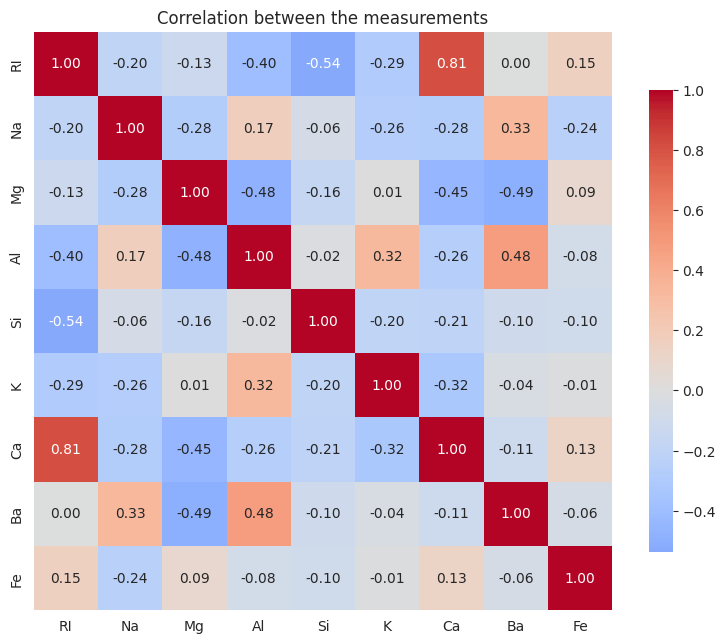

In [12]:
# How the nine measurements relate to each other
plt.figure(figsize=(8, 6.5))
sns.heatmap(glass[features].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation between the measurements')
plt.tight_layout()
plt.show()

The heat map gives the correlation of every pair of measurements, from -1 for two
columns that move in exact opposition to +1 for two that move together, with the
colour running from blue to red.

One value stands out: `RI` and `Ca` correlate at 0.81. That is not a statistical
accident but the physics of the material, since calcium oxide raises the density
of glass and a denser glass bends light more, so the refractive index rises with
the lime content. Those two columns carry largely the same information twice.

The rest of the map is a set of moderate relations that come from the same
constraint, that the percentages have to add up: `RI` against `Si` at -0.54,
`Mg` against `Ba` at -0.49, `Mg` against `Al` at -0.48 and `Al` against `Ba` at
0.48. The last two are the window against non window division showing up as
correlation, since the fragments low in magnesium are the same ones high in
aluminium and barium.

Nothing here forces a column to be dropped. Correlated predictors are a problem
for models that estimate one coefficient per column, because the estimate becomes
unstable when two columns say the same thing, and KNN estimates no coefficients.
The practical effect on a distance is milder and different: `RI` and `Ca` between
them count the same property twice, so density weighs roughly double in the
distance. With nine columns and a dataset this small that is a distortion worth
knowing about rather than a reason to throw away a measurement.

Share of the variation kept by each axis: [0.279 0.229]  total: 0.508


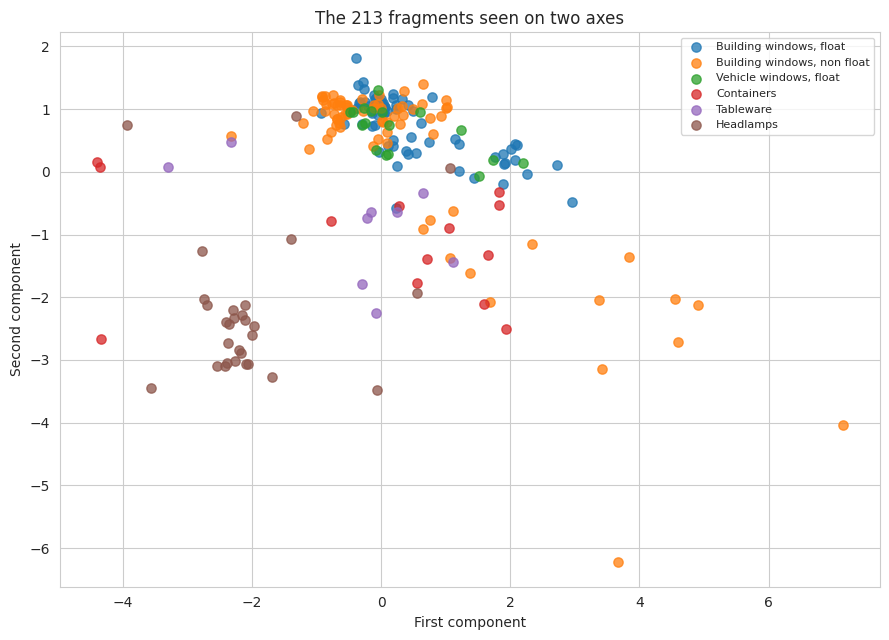

In [13]:
# The nine measurements compressed to two axes so the whole dataset fits in
# one picture. This is a view, not a preparation step: the model reads all nine
standardised = StandardScaler().fit_transform(glass[features])
projection = PCA(n_components=2).fit(standardised)
coords = projection.transform(standardised)
print("Share of the variation kept by each axis:",
      projection.explained_variance_ratio_.round(3),
      " total:", round(projection.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(9, 6.5))
for t in sorted(glass['Type'].unique()):
    mask = (glass['Type'] == t).values
    plt.scatter(coords[mask, 0], coords[mask, 1], label=TYPE_NAMES[t],
                alpha=0.75, s=45)
plt.xlabel('First component')
plt.ylabel('Second component')
plt.title('The 213 fragments seen on two axes')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

This plot compresses the nine measurements into the two directions along which
the fragments differ the most, so the whole dataset can be seen at once. The two
axes together keep 50.8 percent of the variation, which means half the
information is not on the picture and the plot can only be read as a hint.

Even so it says the same thing as the tables. The headlamps form their own group,
well away from everything else, and the containers and tableware sit in loose
clouds of their own. The three window types form a single dense mass in the
middle in which the points of the two kinds of building window are interleaved
rather than side by side, and the vehicle windows are scattered through them with
no region of their own.

For a KNN this picture is the prediction of the result. Where a class occupies
its own region, the neighbours of a new fragment will belong to that class and
the vote will be right. Where three classes share one region, the neighbours will
be a mixture and the vote will go to whichever class is locally denser, which,
given 69 and 76 building windows against 17 vehicle windows, is not going to be
the vehicle windows.

## Data Preparation (CRISP-DM 3)

There is no missing value to impute, no text to encode and no duplicate left to
drop, so the preparation reduces to the two decisions that a distance based model
actually depends on: putting the nine columns on a comparable scale, and
splitting the data in a way that keeps the rare classes on both sides.

In [14]:
# What each column contributes to a distance, before and after scaling.
# For every column the average absolute difference between two fragments is
# computed; a Manhattan distance is exactly the sum of those differences, so the
# share of the total is the weight the column carries in the comparison
def distance_share(values):
    values = np.asarray(values, dtype=float)
    per_column = np.array([np.abs(values[:, j][:, None] - values[:, j][None, :]).mean()
                           for j in range(values.shape[1])])
    return per_column, per_column / per_column.sum() * 100

raw_gap, raw_share = distance_share(glass[features])
scaled_gap, scaled_share = distance_share(StandardScaler().fit_transform(glass[features]))

print(pd.DataFrame({
    'Average difference': raw_gap.round(3),
    'Weight in a raw distance %': raw_share.round(1),
    'Weight after scaling %': scaled_share.round(1),
}, index=features))

    Average difference  Weight in a raw distance %  Weight after scaling %
RI               0.003                         0.1                    12.1
Na               0.863                        15.0                    12.8
Mg               1.413                        24.5                    11.9
Al               0.524                         9.1                    12.8
Si               0.799                        13.8                    12.5
K                0.437                         7.6                     8.1
Ca               1.328                        23.0                    11.3
Ba               0.315                         5.5                     7.7
Fe               0.088                         1.5                    10.9


Every column of this table is one number: how much of a distance between two
fragments that column is responsible for.

Read on raw values, four columns own three quarters of the answer. Magnesium
contributes 24.5 percent, calcium 23.0, sodium 15.0 and silicon 13.8, together
76.3 percent, and they own it because they are the columns written in the largest
numbers, not because they are the most informative. At the other end the
refractive index contributes 0.1 percent, and iron 1.5. Barium, the column that
identifies headlamps almost on its own, contributes 5.5.

In other words, a KNN run on this file as it stands would be comparing fragments
almost exclusively on their magnesium and calcium, and would be effectively blind
to the refractive index that the laboratory measured to five decimal places.

`StandardScaler` removes the mean of each column and divides by its standard
deviation, so every column is expressed in standard deviations of itself and
none can dominate through its unit. The third column of the table shows the
result: the weights become 12.1, 12.8, 11.9, 12.8, 12.5, 8.1, 11.3, 7.7 and 10.9
percent, which is close to the 11.1 percent that nine equal columns would give.
The refractive index goes from 0.1 to 12.1 percent, which is the whole point of
the operation. The two columns that stay below the rest, potassium at 8.1 and
barium at 7.7, are low for a real reason rather than a unit effect: both are zero
in most fragments, and a column that is constant over most of the file genuinely
varies less.

The scaler is fitted inside a `Pipeline` from here on, never on the whole
dataset. If the mean and the standard deviation were computed over all 213
fragments and the data were split afterwards, the test fragments would have
contributed to the transformation applied to the training data, and the test
score would be flattered by information it was not supposed to have.

In [15]:
# Predictors and response
X = glass[features]
y = glass['Type']

# 70 / 30 split. stratify=y keeps the proportion of each origin on both sides,
# which is what makes the split usable at all: tableware has 9 fragments, and a
# random split could easily leave zero of them in the test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print("Training fragments:", len(X_train), " Test fragments:", len(X_test))
print()
print(pd.DataFrame({
    'Training': y_train.value_counts().sort_index(),
    'Test': y_test.value_counts().sort_index(),
    'Training %': (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    'Test %': (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
}))

Training fragments: 149  Test fragments: 64

      Training  Test  Training %  Test %
Type                                    
1           48    21        32.2    32.8
2           53    23        35.6    35.9
3           12     5         8.1     7.8
5            9     4         6.0     6.2
6            7     2         4.7     3.1
7           20     9        13.4    14.1


The split leaves 149 fragments to learn from and 64 to be judged on, and
`stratify` gives both sides nearly the same composition: about 32 percent of
float building windows on each, 36 percent of non float, and so on down to the
4.7 and 3.1 percent of tableware.

The test set is small, and the numbers make the consequence concrete. It holds 2
fragments of tableware, 4 containers and 5 vehicle windows. A single tableware
fragment classified one way or the other moves the recall of that class between
0, 0.5 and 1, and one correct answer anywhere moves the overall accuracy by 1.6
points. No conclusion in this notebook can rest on a difference of a few
fragments in the test set.

That is why the model selection that follows never touches these 64 rows. Every
comparison between values of k, between distances and between selection criteria
is decided by repeated cross validation inside the 149 training fragments, and
the test set is opened once, at the end, to obtain a single estimate on data that
took part in no decision.

## Model of AI (CRISP-DM 4: Modelling)

### How K Nearest Neighbours works

KNN does not build an equation and has nothing to fit. The training set is the
model. To classify a new fragment it computes the distance from that fragment to
every fragment it has stored, keeps the k closest ones and returns the origin
that appears most often among them.

Three choices define the model, and this section decides all three on the
training set.

**k**, the number of neighbours consulted. A small k follows the data closely and
reacts to every isolated fragment; a large k averages over a wide neighbourhood
and, with classes as unequal as these, ends up answering with the majority class
because the neighbourhood eventually fills with building windows.

**The distance**, which defines what close means. Euclidean distance, the
straight line, is the square root of the sum of the squared differences, so one
column that differs a lot dominates the total. Manhattan distance is the plain
sum of the absolute differences, so nine moderate differences count as much as
one large one. With nine columns that split into groups, both are worth testing.

**The vote**, uniform or weighted by distance. With a uniform vote the fifth
neighbour counts as much as the first. With `weights='distance'` each neighbour
counts in inverse proportion to how far it is, which lets k be larger without the
nearest fragments being drowned out by distant ones.

In [16]:
# Repeated stratified cross validation: 5 folds, repeated 5 times with different
# partitions, so every comparison is an average over 25 fits instead of 5. With
# 149 training fragments a single 5 fold run is too noisy to choose anything
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

# A first model with the usual default, k=5 and Euclidean distance
baseline = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])

accuracy = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='accuracy')
macro_f1 = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1_macro')
print("Default KNN, k=5, Euclidean, scaled")
print("  accuracy:", round(accuracy.mean(), 4), "+/-", round(accuracy.std(), 4))
print("  macro F1:", round(macro_f1.mean(), 4), "+/-", round(macro_f1.std(), 4))
print("  always answering the majority class would give:",
      round(y_train.value_counts(normalize=True).max(), 4))

Default KNN, k=5, Euclidean, scaled
  accuracy: 0.6349 +/- 0.068
  macro F1: 0.4935 +/- 0.0784
  always answering the majority class would give: 0.3557


The default configuration reaches an accuracy of 0.635 against a floor of 0.356,
so the nine measurements do carry usable information, and a macro F1 of 0.494.

The gap between those two numbers, fourteen points, is the whole difficulty of
this dataset. The accuracy counts every fragment once, so it is dominated by the
101 building windows out of 149. The macro F1 computes the F1 of each origin
separately and averages the six without regard to their size, so an origin with 7
training fragments weighs as much as one with 53. A model can raise its accuracy
by getting better at building windows while losing tableware entirely, and only
the macro F1 will notice.

Both are reported from here on, and the choice between them as a selection
criterion turns out to change which model gets built.

The best accuracy was 0.6954 with k = 1


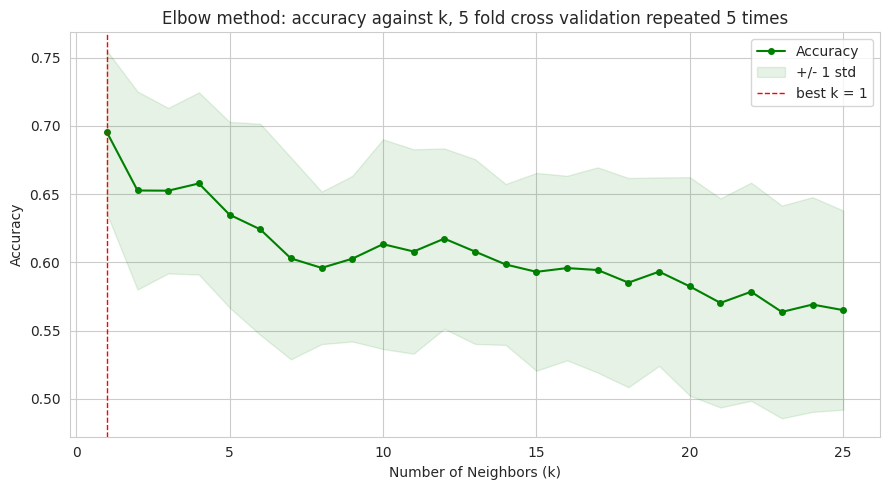

In [17]:
# The elbow method: try every k and look at where the curve turns.
# Each point is the average of 25 fits, and the band is one standard deviation
k_values = list(range(1, 26))
mean_accuracy = np.zeros(len(k_values))
std_accuracy = np.zeros(len(k_values))

for i, k in enumerate(k_values):
    scores = cross_val_score(
        Pipeline([('scaler', StandardScaler()),
                  ('knn', KNeighborsClassifier(n_neighbors=k))]),
        X_train, y_train, cv=cv, scoring='accuracy')
    mean_accuracy[i] = scores.mean()
    std_accuracy[i] = scores.std()

best_k = k_values[int(np.argmax(mean_accuracy))]
print("The best accuracy was", round(mean_accuracy.max(), 4), "with k =", best_k)

plt.figure(figsize=(9, 5))
plt.plot(k_values, mean_accuracy, 'g', marker='o', markersize=4, label='Accuracy')
plt.fill_between(k_values, mean_accuracy - std_accuracy,
                 mean_accuracy + std_accuracy, alpha=0.10, color='green',
                 label='+/- 1 std')
plt.axvline(best_k, color='red', linestyle='--', linewidth=1,
            label='best k = ' + str(best_k))
plt.legend()
plt.ylabel('Accuracy')
plt.xlabel('Number of Neighbors (k)')
plt.title('Elbow method: accuracy against k, 5 fold cross validation repeated 5 times')
plt.tight_layout()
plt.show()

The curve is the elbow method applied to the training set, with the horizontal
axis the number of neighbours consulted and the vertical axis the accuracy
obtained, each point averaged over 25 fits and the shaded band one standard
deviation wide.

It falls almost monotonically. The best value is k = 1 with 0.695, and from there
the curve drops to about 0.60 by k = 8 and keeps sagging to 0.582 at k = 20. The
usual elbow, a rise to an interior maximum and then a decline, does not appear.

That shape is a property of this dataset rather than a fault in the procedure.
Containers, tableware and headlamps have 9, 7 and 20 training fragments in
regions that windows also visit, so as soon as a vote consults ten or fifteen
neighbours it reaches beyond the small class and fills up with building windows.
The classes are too small and too close together for averaging to help. A single
nearest neighbour is noisy by construction, since one atypical stored fragment
decides an answer on its own, but here it is the only setting that lets a class
of nine be predicted at all.

It is also worth noting how wide the band is: roughly 0.06, so about six points
of accuracy separate an unlucky partition from a lucky one. Several of the values
of k on this plot are not distinguishable from each other, which is the reason
the next steps compare whole configurations rather than reading a winner off this
curve.

In [18]:
# What the scaling decided in the preparation section is actually worth,
# measured with the same folds
comparison = []
for k in [1, 3, 5, 7, 10, 15]:
    plain = KNeighborsClassifier(n_neighbors=k, p=1)
    scaled = Pipeline([('scaler', StandardScaler()),
                       ('knn', KNeighborsClassifier(n_neighbors=k, p=1))])
    comparison.append({
        'k': k,
        'Accuracy raw': round(cross_val_score(plain, X_train, y_train, cv=cv,
                                              scoring='accuracy').mean(), 4),
        'Accuracy scaled': round(cross_val_score(scaled, X_train, y_train, cv=cv,
                                                 scoring='accuracy').mean(), 4),
        'Macro F1 raw': round(cross_val_score(plain, X_train, y_train, cv=cv,
                                              scoring='f1_macro').mean(), 4),
        'Macro F1 scaled': round(cross_val_score(scaled, X_train, y_train, cv=cv,
                                                 scoring='f1_macro').mean(), 4),
    })
print(pd.DataFrame(comparison).set_index('k'))

    Accuracy raw  Accuracy scaled  Macro F1 raw  Macro F1 scaled
k                                                               
1         0.7153           0.7250        0.6491           0.6912
3         0.6658           0.6953        0.5655           0.6136
5         0.6375           0.6859        0.5134           0.5584
7         0.6214           0.6443        0.4518           0.4495
10        0.6242           0.6510        0.3759           0.4430
15        0.6296           0.6442        0.3601           0.3666


The table repeats the same cross validation with and without the scaler, at six
values of k, using Manhattan distance in both cases.

On accuracy the difference is modest, one to five points, and at k = 1 it is
almost nothing, 0.715 against 0.725. Read on that column alone one might conclude
that the scaling is a formality.

The macro F1 columns show it is not. At k = 1 the scaling lifts the macro F1 from
0.649 to 0.691, at k = 3 from 0.566 to 0.614 and at k = 5 from 0.513 to 0.558, a
gain of four to five points in the range of k that the model will actually be
built on. The reason follows directly from the weight table: the classes that the
scaling rescues are the ones identified by barium and by the refractive index,
that is headlamps and containers, and those are precisely the small classes that
the accuracy barely counts and the macro F1 counts fully.

From k = 7 upwards the gain disappears and at k = 7 the raw version is even a
fraction ahead, 0.452 against 0.450. That is not an argument against scaling, it
is the small classes being lost by both versions at once: by that point the
neighbourhood is large enough to be filled with building windows whatever the
columns are measured in, and both macro F1 values have fallen to the 0.36 to 0.45
range. The scaling helps where there is still something to save.

This is also the answer to the objection that a small accuracy gain does not
justify a transformation. The scaling is not there to buy a point of accuracy, it
is there so that the model reads the nine measurements the laboratory took rather
than the four that happen to be written in the largest numbers.

In [19]:
# All three choices at once. 25 values of k, two distances and two kinds of vote:
# 100 configurations, each evaluated on the same 25 folds
grid = {
    'knn__n_neighbors': list(range(1, 26)),
    'knn__p': [1, 2],                       # 1 = Manhattan, 2 = Euclidean
    'knn__weights': ['uniform', 'distance'],
}
pipeline = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

search_accuracy = GridSearchCV(pipeline, grid, cv=cv, scoring='accuracy', n_jobs=-1)
search_accuracy.fit(X_train, y_train)

print("Selecting on accuracy")
print("  best configuration:", search_accuracy.best_params_)
print("  cross validated accuracy:", round(search_accuracy.best_score_, 4))

results = pd.DataFrame(search_accuracy.cv_results_)
print("\nBest configuration within each distance and vote:")
print(results.loc[results.groupby(['param_knn__p', 'param_knn__weights'])
                  ['mean_test_score'].idxmax(),
                  ['param_knn__p', 'param_knn__weights', 'param_knn__n_neighbors',
                   'mean_test_score', 'std_test_score']].round(4).to_string(index=False))

Selecting on accuracy
  best configuration: {'knn__n_neighbors': 6, 'knn__p': 1, 'knn__weights': 'distance'}
  cross validated accuracy: 0.7328

Best configuration within each distance and vote:
 param_knn__p param_knn__weights  param_knn__n_neighbors  mean_test_score  std_test_score
            1           distance                       6           0.7328          0.0610
            1            uniform                       1           0.7250          0.0740
            2           distance                       1           0.6954          0.0596
            2            uniform                       1           0.6954          0.0596


The search compares 100 configurations on identical folds and picks k = 6 with
Manhattan distance and a distance weighted vote, at a cross validated accuracy of
0.733, four points above the best the elbow curve found and ten above the default
configuration.

The breakdown by distance and vote is where the useful information is. Manhattan
distance beats Euclidean at both kinds of vote, 0.733 against 0.695 for the
weighted one and 0.725 against 0.695 for the uniform one. That is the expected
outcome for nine columns each carrying a piece of the answer: squaring the
differences, as the Euclidean distance does, lets a single large discrepancy
dominate the comparison, while the Manhattan sum lets the nine measurements
contribute in proportion. Two fragments that differ moderately on several oxides
are treated as different by Manhattan and as similar by Euclidean.

The distance weighted vote also helps, and it interacts with k: with a uniform
vote the best k is 1, while with a weighted vote the score stays flat over a
range of larger k. Weighting by distance lets the model consult more neighbours
without being swamped by them, since the far ones count for little.

The obvious move is to accept k = 6, Manhattan, weighted, and go to the
evaluation. The next cell repeats the search under the other criterion first,
because on a dataset this unbalanced accuracy is not a safe thing to optimise.

In [20]:
# The same 100 configurations, judged on macro F1 instead of accuracy
search_f1 = GridSearchCV(pipeline, grid, cv=cv, scoring='f1_macro', n_jobs=-1)
search_f1.fit(X_train, y_train)

print("Selecting on macro F1")
print("  best configuration:", search_f1.best_params_)
print("  cross validated macro F1:", round(search_f1.best_score_, 4))

results_f1 = pd.DataFrame(search_f1.cv_results_)
print("\nThe eight best configurations:")
print(results_f1.nlargest(8, 'mean_test_score')[
    ['param_knn__n_neighbors', 'param_knn__p', 'param_knn__weights',
     'mean_test_score', 'std_test_score']].round(4).to_string(index=False))

Selecting on macro F1
  best configuration: {'knn__n_neighbors': 1, 'knn__p': 1, 'knn__weights': 'uniform'}
  cross validated macro F1: 0.6912

The eight best configurations:
 param_knn__n_neighbors  param_knn__p param_knn__weights  mean_test_score  std_test_score
                      1             1            uniform           0.6912          0.0872
                      1             1           distance           0.6912          0.0872
                      2             1           distance           0.6912          0.0872
                      3             1           distance           0.6749          0.0759
                      5             1           distance           0.6740          0.0947
                      4             1           distance           0.6683          0.0835
                      7             1           distance           0.6581          0.1052
                      6             1           distance           0.6541          0.1002


Judged on macro F1 the search returns a different model: k = 1 with Manhattan
distance, at 0.691. Manhattan wins again, so that part of the answer is stable,
but the number of neighbours is not. The criterion that counts every class
equally wants a single neighbour; the criterion that counts every fragment
equally wants six.

The mechanism behind the disagreement is the one the elbow curve already showed.
Consulting six neighbours smooths the boundaries, and smoothing pushes the
prediction towards whatever is locally more frequent, which for a region shared
by several origins is the origin with 53 training fragments and not the one with
7. That trade buys overall accuracy and pays for it with the small classes.
Accuracy approves of the trade because the small classes are few. Macro F1
refuses it because they count as much as the large ones.

The next cell measures the trade instead of arguing about it.

In [21]:
# Both candidates classified on the training set only, each fragment predicted by
# the folds that did not contain it, so the comparison uses no test data
candidates = {
    'k=6, Manhattan, weighted (chosen on accuracy)': search_accuracy.best_estimator_,
    'k=1, Manhattan, uniform (chosen on macro F1)': search_f1.best_estimator_,
}

for name, candidate in candidates.items():
    out_of_fold = cross_val_predict(candidate, X_train, y_train, cv=5)
    print('=' * 72)
    print(name)
    print("  accuracy:", round(accuracy_score(y_train, out_of_fold), 4),
          "  macro F1:", round(f1_score(y_train, out_of_fold, average='macro'), 4))
    print(classification_report(
        y_train, out_of_fold,
        target_names=[TYPE_NAMES[t] for t in sorted(y_train.unique())],
        zero_division=0))

k=6, Manhattan, weighted (chosen on accuracy)
  accuracy: 0.7181   macro F1: 0.6625
                             precision    recall  f1-score   support

    Building windows, float       0.66      0.85      0.75        48
Building windows, non float       0.75      0.68      0.71        53
     Vehicle windows, float       0.60      0.25      0.35        12
                 Containers       0.71      0.56      0.62         9
                  Tableware       0.62      0.71      0.67         7
                  Headlamps       0.89      0.85      0.87        20

                   accuracy                           0.72       149
                  macro avg       0.71      0.65      0.66       149
               weighted avg       0.72      0.72      0.71       149

k=1, Manhattan, uniform (chosen on macro F1)
  accuracy: 0.6913   macro F1: 0.6785
                             precision    recall  f1-score   support

    Building windows, float       0.65      0.71      0.68        48
B

Every training fragment here was classified by the folds that did not contain it,
so these two reports compare the candidates without spending the test set. A
single five fold partition is used rather than the repeated one, which is why the
overall figures differ slightly from the search scores above; what is being read
here is the per class breakdown, not the headline number.

The trade shows up exactly where the argument said it would. The model chosen on
accuracy is right more often overall, 0.718 against 0.691, and it owes that to
the largest class: it recovers 85 percent of the float building windows against
71 percent for the other model. The model chosen on macro F1 is ahead on the
average over classes, 0.679 against 0.663, and it owes that to the small ones.
The recall of vehicle windows goes from 0.25 to 0.42, tableware from 0.71 to
0.86 and headlamps from 0.85 to 0.90, while containers stay level at 0.56.

So the accuracy model buys fourteen points of recall on a class of 48 by giving
up seventeen points on a class of 12 and fifteen on a class of 7. That
arithmetic is why the two criteria disagree: counted per fragment the trade is
profitable, counted per class it is not.

That is the trade in numbers, and it decides the model. **The configuration
selected on macro F1, k = 1 with Manhattan distance, is the one taken forward.**

The reason is the problem and not the metric. This is a forensic classifier, and
the question asked of it is what a fragment is, not what most fragments are. A
model that finds one vehicle window in four does not have a small weakness on a
minor class, it has quietly stopped offering one of the six possible answers, and
it will return a confident wrong origin for most of the fragments of that kind it
is ever shown. On a file where three of the six classes have fewer than twenty
examples, that failure is easy to hide behind an accuracy figure, which is
exactly why the criterion was chosen before the test set was opened.

The cost of the decision is stated plainly: k = 1 means every answer rests on one
stored fragment, so the model has no defence against an atypical example in the
training set. With 149 fragments and classes of 7 and 9 that is the price of
keeping those classes reachable at all.

In [22]:
# The chosen model, refitted on the whole training set
best_settings = {name.replace('knn__', ''): value
                 for name, value in search_f1.best_params_.items()}
model = Pipeline([('scaler', StandardScaler()),
                  ('knn', KNeighborsClassifier(**best_settings))])
model.fit(X_train, y_train)
print("Final model:", model.named_steps['knn'])

Final model: KNeighborsClassifier(n_neighbors=1, p=1)


## Evaluation (CRISP-DM 5)

The 64 test fragments have taken part in no decision so far. The scaler was
fitted inside each fold, the value of k, the distance and the vote were chosen by
cross validation on the 149 training fragments, and the criterion for that choice
was argued from the problem before the result was known. What follows is
therefore a single honest estimate, read with the reservation that 64 fragments
is a small sample.

In [23]:
# The chosen model on data it has never seen
predictions = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Test macro F1:", round(f1_score(y_test, predictions, average='macro'), 4))
print("Majority class baseline:", round(y_test.value_counts(normalize=True).max(), 4))
print()
print("Cross validated estimate on the training set was",
      round(search_f1.best_score_, 4), "macro F1")

Test accuracy: 0.75
Test macro F1: 0.7323
Majority class baseline: 0.3594

Cross validated estimate on the training set was 0.6912 macro F1


The model classifies 48 of the 64 test fragments correctly, an accuracy of 0.750
against a majority class floor of 0.359, and reaches a macro F1 of 0.732.

The macro F1 on the test set, 0.732, is four points above the 0.691 that the
cross validation predicted. The direction is the reassuring one, since a test
score far below the cross validated estimate would mean the selection had overfit
the folds, but the size of the gap should not be read as the model being better
than expected. Four points on 64 fragments is two or three fragments, well inside
the variation the training folds themselves showed.

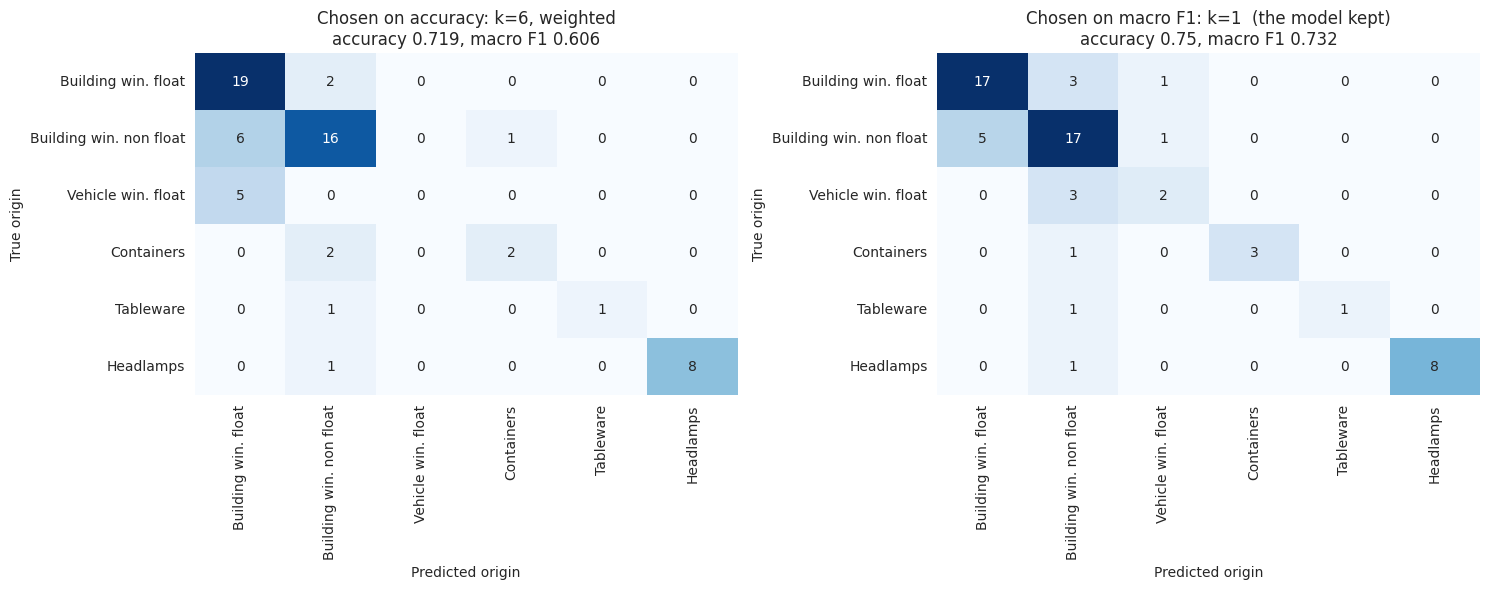

In [24]:
# The confusion matrices of the two candidates, side by side
predictions_accuracy = search_accuracy.best_estimator_.predict(X_test)
labels_present = sorted(y_test.unique())
short_names = [TYPE_NAMES[t].replace(' windows, ', ' win. ') for t in labels_present]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pairs = [(predictions_accuracy, 'Chosen on accuracy: k=6, weighted'),
         (predictions, 'Chosen on macro F1: k=1  (the model kept)')]
for ax, (preds, title) in zip(axes, pairs):
    matrix = confusion_matrix(y_test, preds, labels=labels_present)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=short_names, yticklabels=short_names)
    ax.set_title(title + '\naccuracy ' + str(round(accuracy_score(y_test, preds), 3))
                 + ', macro F1 ' + str(round(f1_score(y_test, preds, average='macro'), 3)))
    ax.set_xlabel('Predicted origin')
    ax.set_ylabel('True origin')
plt.tight_layout()
plt.show()

Each matrix has the true origin down the side and the predicted origin along the
top, so the diagonal holds the fragments classified correctly and everything off
it is an error, read as confused this for that.

The two matrices show the trade of the modelling section carried onto the test
set, and they show it more sharply than the cross validation did.

The model on the left, chosen on accuracy, is right slightly less often overall
here, 0.719 against 0.750, and its row for vehicle windows is empty on the
diagonal: all 5 are classified as something else, and its column contains no
prediction at all. It also finds only 1 of the 2 tableware fragments and 2 of the
4 containers. Its macro F1 is 0.606.

The model on the right, the one kept, recovers 2 of the 5 vehicle windows and 3
of the 4 containers, at the cost of a few building windows misread as each other.
On this particular test set it is ahead on both metrics at once, which is a bonus
rather than the argument: it was selected for the second one.

The dominant error in both is the same block in the top left corner, between the
two kinds of building window, which is the pair the exploration measured at 0.19
standard deviations apart. And the vehicle windows, the class at 0.10 standard
deviations from float building windows, are still mostly absorbed into them even
by the model that was tuned to find them.

In [25]:
# Per class results of the model that was kept
print(classification_report(
    y_test, predictions,
    target_names=[TYPE_NAMES[t] for t in labels_present],
    zero_division=0))

                             precision    recall  f1-score   support

    Building windows, float       0.77      0.81      0.79        21
Building windows, non float       0.65      0.74      0.69        23
     Vehicle windows, float       0.50      0.40      0.44         5
                 Containers       1.00      0.75      0.86         4
                  Tableware       1.00      0.50      0.67         2
                  Headlamps       1.00      0.89      0.94         9

                   accuracy                           0.75        64
                  macro avg       0.82      0.68      0.73        64
               weighted avg       0.76      0.75      0.75        64



The report splits the 64 answers into three rates per origin. Precision is how
often the model is right when it names that origin, recall is how many fragments
of that origin it found, and F1 is the balance between them.

The results split into three groups.

Headlamps, containers and tableware are handled well, with precisions of 1.00 and
recalls of 0.89, 0.75 and 0.50. When the model names one of these three it is
right every time, which is the chemistry doing the work: barium for the
headlamps, the low magnesium and high calcium for the containers. The recall of
0.50 for tableware is one fragment out of two and carries no statistical meaning
on its own.

The two building window classes reach F1 scores of 0.79 and 0.69 on 21 and 23
fragments, so roughly three quarters of the bulk of the file is classified
correctly, with the errors going between the two of them.

Vehicle windows are the failure, at a precision of 0.50 and a recall of 0.40, so
2 of 5 found. This is the confusion the problem analysis identified as the one
that matters and the exploration predicted from the average profiles, and it is
not a defect of the model. Float vehicle windows and float building windows are
made by the same process from nearly the same recipe, and the nine measurements
in this file do not carry enough to separate them. No choice of k would have
fixed it.

The honest statement of the result for a forensic use is therefore split. The
model can tell a headlamp, a container or a piece of tableware from a window and
can be trusted when it names one. It can also tell that a fragment is a window.
It cannot reliably tell a car window from a house window, and it should not be
used to make that particular claim.

No ROC curve is drawn for this model. A ROC curve needs a score that can be cut
at different points, and a KNN with k = 1 returns only 0 or 1 for each origin,
because its single neighbour either belongs to that origin or does not. Every
cut gives the same point, so the curve would have nothing to show. The ROC curve
is used in the SVM notebook, where the model returns a graded score.

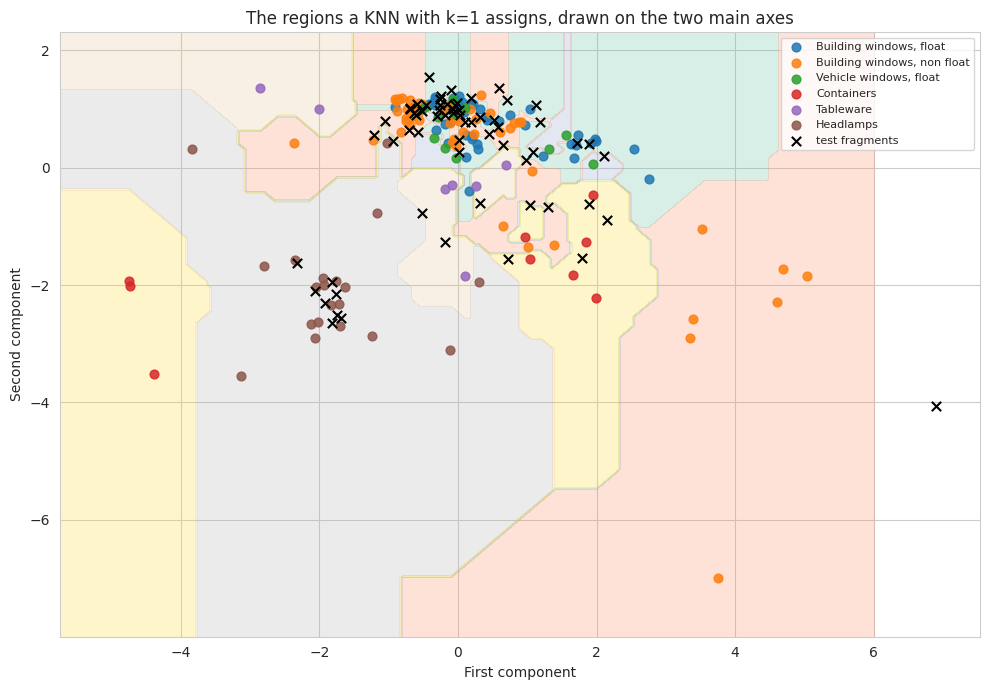

In [26]:
# What the classifier is doing, drawn on the two axes of the exploration.
# The model shown here reads only those two axes, so it is an illustration of the
# mechanism and not the model that was evaluated above
view = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=2))]).fit(X_train)
train_2d = view.transform(X_train)
test_2d = view.transform(X_test)

illustration = KNeighborsClassifier(
    n_neighbors=model.named_steps['knn'].n_neighbors,
    p=model.named_steps['knn'].p,
    weights=model.named_steps['knn'].weights).fit(train_2d, y_train)

step = 0.05
x_min, x_max = train_2d[:, 0].min() - 1, train_2d[:, 0].max() + 1
y_min, y_max = train_2d[:, 1].min() - 1, train_2d[:, 1].max() + 1
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, step),
                             np.arange(y_min, y_max, step))
zone = illustration.predict(np.c_[grid_x.ravel(), grid_y.ravel()]).reshape(grid_x.shape)

plt.figure(figsize=(10, 7))
plt.contourf(grid_x, grid_y, zone, alpha=0.25, levels=np.arange(0.5, 8, 1),
             cmap='Set2')
for t in labels_present:
    mask = (y_train == t).values
    plt.scatter(train_2d[mask, 0], train_2d[mask, 1], s=40, alpha=0.85,
                label=TYPE_NAMES[t])
plt.scatter(test_2d[:, 0], test_2d[:, 1], marker='x', c='black', s=45,
            label='test fragments')
plt.xlabel('First component')
plt.ylabel('Second component')
plt.title('The regions a KNN with k=' + str(model.named_steps['knn'].n_neighbors)
          + ' assigns, drawn on the two main axes')
plt.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

The coloured regions are the answer the classifier gives at each point of the
plane, the dots are the training fragments and the black crosses the test ones.
The model drawn here was refitted on the two components alone so that its
decision could be drawn at all, which is why the picture explains the mechanism
rather than reproducing the exact numbers of the evaluation.

Two things are visible. The regions are ragged rather than smooth, with small
islands of one colour inside another, which is what k = 1 produces: every stored
fragment claims the territory around it, and one atypical fragment creates an
island. That is the cost of the choice made in the modelling section, in picture
form.

The second is the middle of the plot, where the three window classes overlap and
the regions become a mosaic of two or three colours with no boundary between
them. A test cross falling in that area gets its answer from whichever training
dot is nearest, and that is close to arbitrary. The clean part of the picture is
around the edges, where headlamps and containers hold uninterrupted territory,
and that is exactly the part of the problem the model solves well.

## Results (CRISP-DM 6: Deployment)

### Saving the model

A fitted KNN is only useful outside the notebook if what travels with it is the
whole decision. For this model that is the pipeline, since the scaler holds the
mean and the standard deviation of the 149 training fragments and a new fragment
has to be transformed with exactly those numbers before any distance is computed,
and the map from the numeric code to the name of the origin.

In [27]:
# What is saved: the fitted pipeline, the columns it expects in order, and the
# meaning of the codes it returns
bundle = {'model': model,
          'columns': list(X.columns),
          'type_names': TYPE_NAMES}

joblib.dump(bundle, 'model_glass_knn.pkl', compress=3)
print("Size on disk:", round(os.path.getsize('model_glass_knn.pkl') / 1024, 1), "KB")

# Load it back and check it gives the same answers
restored = joblib.load('model_glass_knn.pkl')
same = (restored['model'].predict(X_test) == predictions).all()
print("The copy loaded from disk gives the same predictions:", same)

Size on disk: 9.4 KB
The copy loaded from disk gives the same predictions: True


In [28]:
# The model working fragment by fragment on a sample of the test set, up to two
# fragments of each origin
sample_index = y_test.groupby(y_test).head(2).index
sample = X_test.loc[sample_index]
answer = restored['model'].predict(sample)
vote = restored['model'].predict_proba(sample).max(axis=1)

report = pd.DataFrame({
    'Mg': sample['Mg'].values,
    'Al': sample['Al'].values,
    'Ba': sample['Ba'].values,
    'True origin': [TYPE_NAMES[t] for t in y_test.loc[sample_index]],
    'Predicted': [TYPE_NAMES[t] for t in answer],
    'Vote': vote.round(2),
})
report['Correct'] = np.where(report['True origin'] == report['Predicted'], 'yes', 'no')
print(report.to_string(index=False))
print("\nCorrect in this sample:", (report['Correct'] == 'yes').sum(), "of", len(report))

  Mg   Al   Ba                 True origin                   Predicted  Vote Correct
0.00 1.76 0.00                  Containers                  Containers   1.0     yes
3.47 1.79 0.00 Building windows, non float Building windows, non float   1.0     yes
3.43 1.40 0.00     Building windows, float     Building windows, float   1.0     yes
2.88 1.71 0.00 Building windows, non float Building windows, non float   1.0     yes
0.00 2.25 0.63                   Headlamps                   Headlamps   1.0     yes
3.67 1.16 0.00     Building windows, float     Building windows, float   1.0     yes
3.65 0.65 0.00      Vehicle windows, float      Vehicle windows, float   1.0     yes
3.54 0.75 0.15      Vehicle windows, float Building windows, non float   1.0      no
0.00 1.98 1.57                   Headlamps                   Headlamps   1.0     yes
1.88 1.56 0.00                  Containers                  Containers   1.0     yes
0.78 1.74 0.00                   Tableware                   Tabl

The table is the saved model answering one fragment at a time, with three of the
nine measurements printed next to each answer so the decision can be followed.

Ten of the twelve are classified correctly, and the three columns printed explain
most of that. The two fragments carrying substantial barium, 0.63 and 1.57, are
both called headlamps and both are headlamps. Magnesium separates the rest: every
fragment above 2.8 percent is a window and is called a window, while the
fragments at or near zero are the containers, the tableware and the headlamps.

The two errors are instructive rather than careless. The first is a vehicle
window with 3.54 percent of magnesium and 0.75 of aluminium, called a non float
building window; the row above it is a real vehicle window at 3.65 and 0.65, and
the building windows a few rows up sit at 3.43 and 1.40. The three are the same
glass to within the precision of the measurement, which is the confusion the
exploration measured at 0.10 standard deviations. The second is a piece of
tableware with no magnesium and 0.56 percent of aluminium, the lowest aluminium
in the sample, which puts it in a corner of the space where the nearest stored
fragment happens to be a window. With k = 1 there is nothing to outvote that
neighbour.

The vote column is 1.00 on every row because k = 1: the single neighbour
consulted always agrees with itself. This is the practical drawback of the
configuration chosen, and it has to be stated for anyone deploying the model. It
returns an origin but it cannot express doubt, so a fragment that falls in the
middle of the window cloud, where the answer is close to arbitrary, arrives with
the same apparent certainty as a headlamp identified by its barium. If a
confidence value were needed in use, the k = 6 weighted model would provide one,
at the cost of never returning the rare origins.

### Conclusions

A K Nearest Neighbours classifier was trained on 149 glass fragments and judged
on 64 that took part in no decision, to identify the origin of a fragment from
its refractive index and eight oxide percentages.

The three settings of the model were chosen inside the training set by five fold
cross validation repeated five times, over a grid of 100 configurations:
Manhattan distance, which beat Euclidean at both kinds of vote because nine
moderate differences say more here than one large one; a single neighbour; and a
uniform vote. All nine columns were standardised first, which the preparation
section justified by measuring that on raw values magnesium and calcium alone
carried 48 percent of every distance while the refractive index carried 0.1
percent.

The model reaches an accuracy of 0.750 and a macro F1 of 0.732 on the test set,
against a majority class floor of 0.359.

The result that decided the shape of this notebook is the disagreement between
the two selection criteria. Optimising accuracy returned k = 6 with a distance
weighted vote and a model that classified all five test vehicle windows as
something else and found one of two tableware fragments; optimising macro F1
returned k = 1 and a model that recovers part of both. Since the purpose is to
name what a fragment is, not to be right about the common case, the second was
kept, and the choice was made from the problem before the test set was opened.

The model is usable for part of the forensic question and not for the rest. It
identifies headlamps, containers and tableware with a precision of 1.00 on this
test set, so when it names one of those three it can be believed, and the
chemistry behind that is visible in the data: barium is present in 90 percent of
headlamps and in 15 percent or less of every other origin, and magnesium is
absent from 79 percent of the headlamps and 54 percent of the containers against
none of the float windows. It cannot distinguish a float vehicle window from a
float building window, at a recall of 0.40 on five fragments, and the exploration
predicted this before any model was fitted, since the average profiles of those
two origins sit 0.10 standard deviations apart while every other pair of origins
sits at 0.68 or above. That is a limit of the nine measurements, not of KNN.

Two constraints should travel with these numbers. The test set holds 64
fragments, so a single answer moves the accuracy by 1.6 points and the recalls of
the small classes are computed on two to five cases each. And k = 1 makes every
answer depend on one stored fragment, which leaves the model without any way to
signal that a fragment fell in the region where the three window types overlap
and its answer is close to a guess.

What would move the result is more data rather than a different model. Nine
fragments of tableware and 17 vehicle windows are too few for any classifier to
learn a reliable boundary, and the specific confusion that limits this one would
need a measurement the file does not contain, such as the thickness of the
fragment or the presence of a coating, which is what a laboratory would actually
use to tell a windscreen from a house window.